In [5]:
!pip install numpy
!pip install pandas
!pip install plotly-express
!pip install matplotlib
!pip install scikit-learn
!pip install tensor-flow
!pip install keras
!pip install tensorflow


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not find a version that satisfies the requirement tensor-flow (from versions: none)
ERROR: No matching distribution found for tensor-flow

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mlp
import warnings
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.regularizers import L2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.backend import clear_session
from itertools import product
import time

# Loading and Visualizing Dataset
## Loading Dataset

In [2]:
#Loading dataset
df_original = pd.read_csv("pedestrian_counts_T1.csv")

#parsing data
data_parsed = df_original["data"][0].split(",")
sensor_name = df_original["series_name"]
start_timestamp = pd.to_datetime(df_original["start_timestamp"][0])

#reconstructing dataframe with parsed data
df = pd.DataFrame(data_parsed, columns=["pedestrian count"])
df["pedestrian count"] = df["pedestrian count"].astype(int)
df["time_stamp"] = start_timestamp + pd.Timedelta(hours=1)*df.index
df = df.set_index("time_stamp")

print("DF SHAPE: ", df.shape)

df.head()

DF SHAPE:  (84331, 1)


,pedestrian count
time_stamp,
2009-05-01 00:00:00-01:00,53
2009-05-01 01:00:00-01:00,43
2009-05-01 02:00:00-01:00,10
2009-05-01 03:00:00-01:00,5
2009-05-01 04:00:00-01:00,25


# Dataset Audit

In [3]:
print("\nMissing values:")
print(df.isna().sum())

print("\nRows with missing Pedestrian Counts:")
display(df.loc[df["pedestrian count"].isna()])


Missing values:
pedestrian count    0
dtype: int64

Rows with missing Pedestrian Counts:


,pedestrian count
time_stamp,


## Dataset Visualization

In [9]:
#dataset visualization of total time frame with slidebar
fig = px.line(df, y="pedestrian count")
fig.update_xaxes(rangeslider_visible=True)
fig.show()

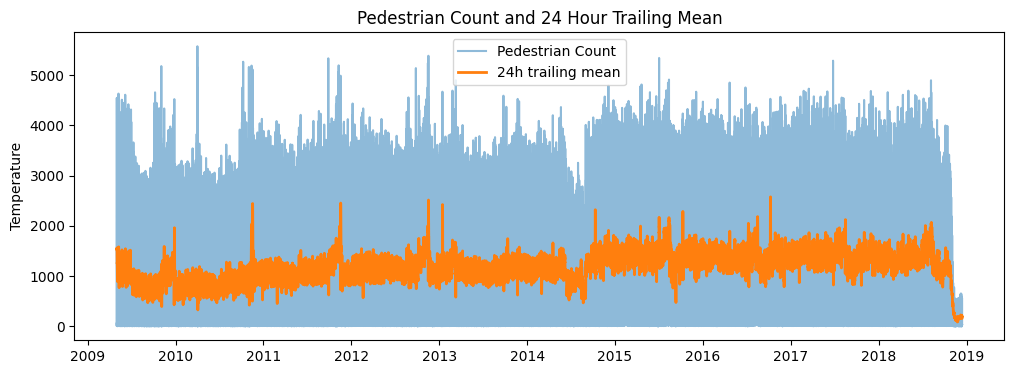

In [10]:
# 2B. AvgTemp with a 30-day rolling mean
rolling_daily_mean = df["pedestrian count"].rolling(24, center=False).mean()

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["pedestrian count"], alpha=0.5, label="Pedestrian Count")
plt.plot(rolling_daily_mean.index, rolling_daily_mean, linewidth=2, label="24h trailing mean")
plt.title("Pedestrian Count and 24 Hour Trailing Mean")
plt.ylabel("Temperature")
plt.legend()
plt.show()

<Axes: title={'center': 'Distribution over in 2010'}, xlabel='Date', ylabel='Pedestrian Count'>

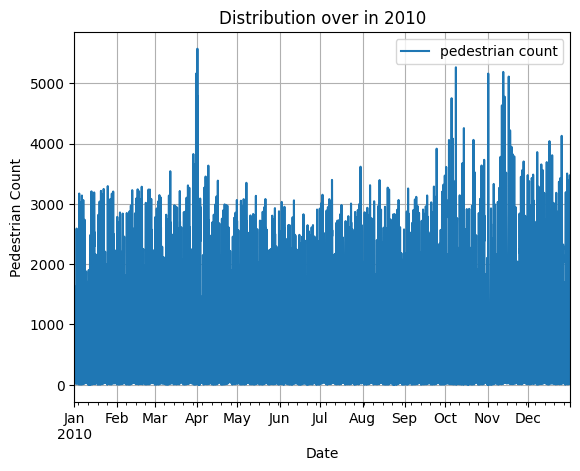

In [11]:
#dataset visualization of 2010 (Checking for seasonality)
df_2010 = df.loc["2010"]
df_2010.plot(title="Distribution over in 2010", ylabel='Pedestrian Count', xlabel="Date", grid=True)

Text(0, 0.5, 'Pedestrian Count')

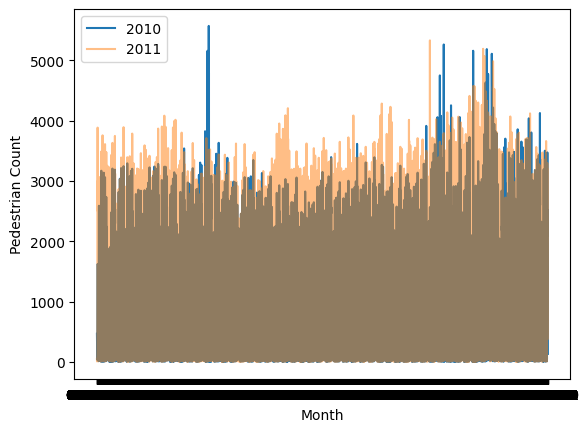

In [12]:
df_2011 = df.loc["2011"]

df_2010["month_day_hour"] = df_2010.index.strftime("%m-%d %H")
df_2011["month_day_hour"] = df_2011.index.strftime("%m-%d %H")

plt.plot(df_2010['month_day_hour'],df_2010['pedestrian count'])
plt.plot(df_2011['month_day_hour'],df_2011['pedestrian count'],alpha=0.5)
plt.legend(['2010', '2011'])
plt.xlabel('Month')
plt.ylabel('Pedestrian Count')

array([[<Axes: title={'center': 'pedestrian count'}>]], dtype=object)

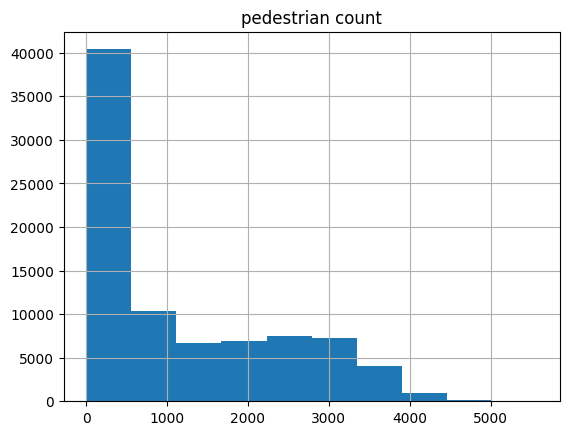

In [13]:
#plotting pedestrian count histogram
df.hist()

# Preprocessing
## Chronological Split

Train: 2009-05-01 to 2015-02-07 50598
Validation: 2015-02-07 to 2017-01-09 16866
Test: 2017-01-10 to 2018-12-13 16867


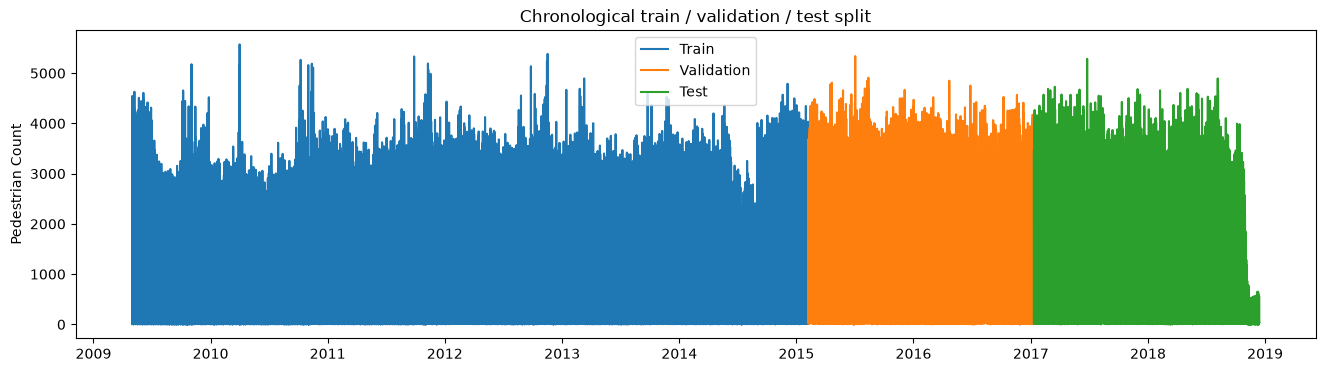

In [4]:
train_end = int(len(df) * 0.60)
val_end = int(len(df) * 0.80)

train_set = df.iloc[:train_end].copy()
val_set = df.iloc[train_end:val_end].copy()
test_set = df.iloc[val_end:].copy()

print("Train:", train_set.index.min().date(), "to", train_set.index.max().date(), len(train_set))
print("Validation:", val_set.index.min().date(), "to", val_set.index.max().date(), len(val_set))
print("Test:", test_set.index.min().date(), "to", test_set.index.max().date(), len(test_set))

plt.figure(figsize=(16, 4))
plt.plot(train_set.index, train_set["pedestrian count"], label="Train")
plt.plot(val_set.index, val_set["pedestrian count"], label="Validation")
plt.plot(test_set.index, test_set["pedestrian count"], label="Test")
plt.title("Chronological train / validation / test split")
plt.ylabel("Pedestrian Count")
plt.legend()
plt.show()

## Scaler and Imputer

In [5]:
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_set)
val_scaled = scaler.transform(val_set)
test_scaled = scaler.transform(test_set)

## Making Window

In [6]:
def make_windows(values, lookback):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])
    return np.asarray(X), np.asarray(y)

X_train, y_train = make_windows(train_scaled, lookback=12)
X_val, y_val = make_windows(val_scaled, lookback=12)
X_test, y_test = make_windows(test_scaled, lookback=12)

print("New Shape: ", X_train.shape)

New Shape:  (50586, 12, 1)


# Baseline

In [17]:
#function for output metrics of prediction
def evaluate_predictions(label, y_actual, y_pred):
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2score = r2_score(y_actual, y_pred)

    print(label, "MAE:", mae)
    print(label, "RMSE:", rmse)
    print(label, "R2:", r2score)

    return mae, rmse, r2score

#Niave Baseline
y_val_baseline = np.roll(y_val, 1)
y_test_baseline = np.roll(y_test, 1)

#filling in the first value with the last value from train dataset
y_val_baseline[0] = y_train[-1]
y_test_baseline[0] = y_test_baseline[-1]

val_baseline_mae, val_baseline_rmse, val_baseline_r2 = evaluate_predictions("Validation Niave Baseline", y_val, y_val_baseline)
test_baseline_mae, test_baseline_rmse, test_baseline_r2 = evaluate_predictions("Test Niave Baseline", y_test, y_test_baseline)

baseline_performance = {
    "Model" : "Niave Baseline",
    "Test MAE" : test_baseline_mae,
    "Test RMSE" : test_baseline_rmse,
    "Test R2" : test_baseline_r2,
    "Train Time" : 0,
    "Baseline Improvement" : 0
}

Validation Niave Baseline MAE: 0.29601051971350645
Validation Niave Baseline RMSE: 0.4148279647463359
Validation Niave Baseline R2: 0.8769027595202032
Test Niave Baseline MAE: 0.28055230959053823
Test Niave Baseline RMSE: 0.4023375688801395
Test Niave Baseline R2: 0.8795390033708282


# MLP
## Grid Search

In [18]:
param_grid = {
    "units": [16,32, 64],
    "learning_rate": [0.01, 0.001, 0.0001],
    "l2_reg": [0, 0.01, 0.1],
}

grid_results = []

for units, learning_rate, l2_reg, in product(param_grid["units"], param_grid["learning_rate"], param_grid["l2_reg"]):
    clear_session()

    candidate = Sequential()
    candidate.add(Input(shape=(12,)))
    candidate.add(Dense(units, kernel_regularizer=L2(l2_reg), activation='relu'))
    candidate.add(Dense(1))

    candidate.compile(optimizer=Adam(learning_rate=learning_rate), loss="mse")

    early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

    candidate_history = candidate.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=64, shuffle=False, callbacks=[early_stop], verbose=0)

    y_pred = candidate.predict(X_val, verbose=0)

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    grid_results.append({
        "units": units,
        "learning_rate": learning_rate,
        "l2_reg" : l2_reg,
        "validation_RMSE": rmse,
        "epochs_trained": len(candidate_history.history["loss"])
    })

grid_results = pd.DataFrame(grid_results).sort_values("validation_RMSE").reset_index(drop=True)
display(grid_results)

mlp_best_units = int(grid_results.iloc[0]["units"])
mlp_best_learning_rate = float(grid_results.iloc[0]["learning_rate"])
mlp_best_l2_reg = float(grid_results.iloc[0]["l2_reg"])

print("Best params and results: ", grid_results.iloc[0])

,units,learning_rate,l2_reg,validation_RMSE,epochs_trained
0,64,0.0010,0.00,0.157604,50
1,16,0.0010,0.00,0.167981,50
2,64,0.0001,0.00,0.173893,50
3,16,0.0100,0.00,0.174031,23
4,64,0.0100,0.00,0.175259,21
5,32,0.0100,0.00,0.176198,19
6,32,0.0010,0.00,0.178845,13
7,32,0.0001,0.00,0.180669,50
8,64,0.0010,0.01,0.181943,22
9,16,0.0010,0.01,0.182804,50


Best params and results:  units              64.000000
learning_rate       0.001000
l2_reg              0.000000
validation_RMSE     0.157604
epochs_trained     50.000000
Name: 0, dtype: float64


## Training and Evaluating Optimized MLP

In [10]:
#Hard coding optimized parameters to avoid rerunning grid search
mlp_best_units = 64
mlp_best_l2_reg = 0
mlp_best_learning_rate = 0.001000

In [11]:
mlp_model = Sequential()
mlp_model.add(Input(shape=(12,)))
mlp_model.add(Dense(mlp_best_units, kernel_regularizer=L2(mlp_best_l2_reg), activation='relu'))
mlp_model.add(Dense(1))

mlp_model.compile(optimizer=Adam(learning_rate=mlp_best_learning_rate), loss="mse")

early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

start_time = time.time()

mlp_history = mlp_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, shuffle=False, callbacks=[early_stop], verbose=0)

end_time = time.time()

mlp_train_time = end_time - start_time
print("MLP Train Time:", mlp_train_time)

MLP Train Time: 408.89700865745544


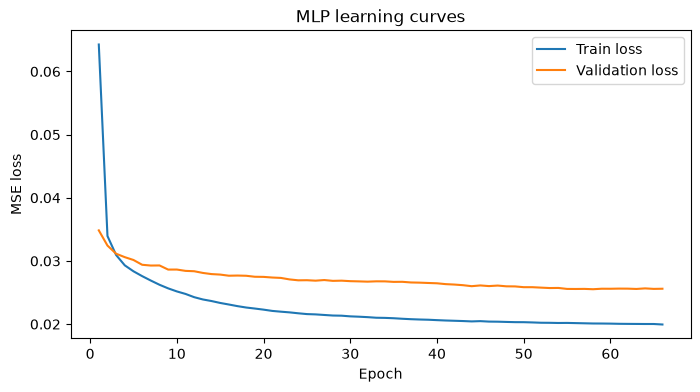

Epochs stopped at 66
MLP Validation MAE: 0.10390097837276746
MLP Validation RMSE: 0.15976793903157888
MLP Validation R2: 0.9817403885579572
MLP Test MAE: 0.11207135437088799
MLP Test RMSE: 0.16635855288739942
MLP Test R2: 0.9794052964449553


In [23]:

def plot_loss(title, history):
    plt.figure(figsize=(8, 4))
    plt.plot(np.arange(1, len(history.history["loss"])+1), history.history["loss"], label="Train loss")
    plt.plot(np.arange(1, len(history.history["val_loss"])+1), history.history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.title(title)
    plt.legend()
    plt.show()

plot_loss("MLP learning curves", mlp_history)

val_pred = mlp_model.predict(X_val, verbose=0)
test_pred = mlp_model.predict(X_test, verbose=0)

print("Epochs stopped at", len(mlp_history.history["loss"]))

val_mlp_mae, val_mlp_rmse, val_mlp_r2 = evaluate_predictions("MLP Validation", y_val, val_pred)
test_mlp_mae, test_mlp_rmse, test_mlp_r2 = evaluate_predictions("MLP Test", y_test, test_pred)


mlp_performance = {
    "Model" : "Optimized MLP",
    "Test MAE" : test_mlp_mae,
    "Test RMSE" : test_mlp_rmse,
    "Test R2" : test_mlp_r2,
    "Train Time" : mlp_train_time,
    "Baseline Improvement" : 100 * (test_baseline_rmse - test_mlp_rmse) / test_mlp_rmse
}

# CNN
## Grid Search

## Training and Evaluating Optimized CNN

In [ ]:
param_grid = {
    "kernel": [3,5,7],
    "filters": [8, 16, 32],
    "learning_rate": [0.01, 0.001, 0.0001],
    "dropout": [0, 0.3, 0.5],
}

grid_results = []

for kernel, filters, learning_rate, in product(param_grid["kernel"], param_grid["filters"], param_grid["learning_rate"]):
    clear_session()

    candidate = Sequential()
    candidate.add(Conv1D(filters=filters, kernel_size=kernel, activation="relu", padding="same"))
    candidate.add(MaxPooling1D(pool_size=2))
    candidate.add(Flatten())
    candidate.add(Dense(32, activation="relu"))
    candidate.add(Dense(1))

    candidate.compile(optimizer=Adam(learning_rate=learning_rate), loss="mse")

    early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

    candidate_history = candidate.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, shuffle=False, callbacks=[early_stop], verbose=0)

    y_pred = candidate.predict(X_val, verbose=0)

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    grid_results.append({
        "kernel": kernel,
        "learning_rate": learning_rate,
        "filters" : filters,
        "validation_RMSE": rmse,
        "epochs_trained": len(candidate_history.history["loss"])
    })

grid_results = pd.DataFrame(grid_results).sort_values("validation_RMSE").reset_index(drop=True)
display(grid_results)

cnn_best_kernel = int(grid_results.iloc[0]["kernel"])
cnn_best_filters = float(grid_results.iloc[0]["filters"])
cnn_best_learning_rate = float(grid_results.iloc[0]["learning_rate"])

print("Best params and results: ", grid_results.iloc[0])

,kernel,learning_rate,filters,validation_RMSE,epochs_trained
0,5,0.0010,32,0.152779,47
1,3,0.0010,16,0.152926,37
2,7,0.0010,8,0.154097,27
3,3,0.0010,8,0.155747,28
4,5,0.0001,16,0.156379,100
5,5,0.0001,32,0.156488,100
6,7,0.0010,16,0.156650,18
7,5,0.0010,8,0.156745,25
8,7,0.0001,16,0.157132,100
9,7,0.0001,32,0.157160,100


Best params and results:  kernel              5.000000
learning_rate       0.001000
filters            32.000000
validation_RMSE     0.152779
epochs_trained     47.000000
Name: 0, dtype: float64


In [18]:
#Hard coding optimized parameters to avoid rerunning grid search
cnn_best_kernels = 64
cnn_best_filters = 32
cnn_best_learning_rate = 0.001000

In [20]:
cnn_model = Sequential()
cnn_model.add(Conv1D(filters=cnn_best_filters, kernel_size=cnn_best_kernels, activation="relu", padding="same"))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Flatten())
cnn_model.add(Dense(32, activation="relu"))
cnn_model.add(Dense(1))

cnn_model.compile(optimizer=Adam(learning_rate=cnn_best_learning_rate), loss="mse")

early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

start_time = time.time()

cnn_history = cnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, shuffle=False, callbacks=[early_stop], verbose=0)

end_time = time.time()

cnn_train_time = end_time - start_time
print("CNN Train Time:", cnn_train_time)

CNN Train Time: 488.14171862602234


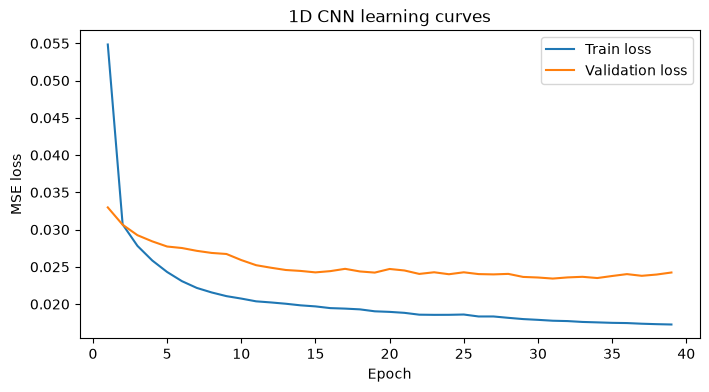

Epochs stopped at 39
MLP Validation MAE: 0.09780357794219256
MLP Validation RMSE: 0.1530579262128561
MLP Validation R2: 0.9832419332742189
MLP Test MAE: 0.10262900849003662
MLP Test RMSE: 0.15494073152438828
MLP Test R2: 0.9821352689906192


In [22]:
plot_loss("1D CNN learning curves", cnn_history)

val_pred = cnn_model.predict(X_val, verbose=0)
test_pred = cnn_model.predict(X_test, verbose=0)

print("Epochs stopped at", len(cnn_history.history["loss"]))

val_cnn_mae, val_cnn_rmse, val_cnn_r2 = evaluate_predictions("MLP Validation", y_val, val_pred)
test_cnn_mae, test_cnn_rmse, test_cnn_r2 = evaluate_predictions("MLP Test", y_test, test_pred)


cnn_performance = {
    "Model" : "Optimized CNN",
    "Test MAE" : test_cnn_mae,
    "Test RMSE" : test_cnn_rmse,
    "Test R2" : test_cnn_r2,
    "Train Time" : cnn_train_time,
    "Baseline Improvement" : 100 * (test_baseline_rmse - test_cnn_rmse) / test_cnn_rmse
}

# Model Comparison

In [26]:
comparison_table = pd.DataFrame([baseline_performance, mlp_performance, cnn_performance])
comparison_table

,Model,Test MAE,Test RMSE,Test R2,Train Time,Baseline Improvement
0,Niave Baseline,0.280552,0.402338,0.879539,0.000000,0.000000
1,Optimized MLP,0.112071,0.166359,0.979405,408.897009,141.849645
2,Optimized CNN,0.102629,0.154941,0.982135,488.141719,159.671918
